# _Hands-on activity #1_

## Learning goals: 
 1. Obtaining and visualizing elevation models from an online database using `victor.py`
 2. Converting coordinate system using `pyproj`
 3. Plotting and manipulating data using `matplotlib` and `numpy`
 
 ### To serve as a reference, code outputs are provided.

## Pick a volcano, and make a note of its longitude and latitude.

In [1]:
lon = -22.2725

lat = 63.905

## Python's strengths are in its packages, which we'll import a few of now!

In [2]:
import pyproj
import numpy
import matplotlib.pyplot as plt
import sys
import rioxarray as rxr
import cartopy.crs as ccrs
import pandas as pd
sys.path.insert(0,"/home/jovyan/shared/Libraries")
import victor

## We need to determine the UTM coordinates of the volcano. Let's change the projection/CRS.
#### (Hint: Use `pyproj`)

### <span style="color:blue"> Solution Notes: Below, i use the `Proj 4` format to convert my coordinates. However, using `pyproj.Transformer` works just as well, as long as two EPSG values from https://epsg.io/ are provided </span>

In [3]:
myProj = pyproj.Proj("+proj=utm +zone=27 +ellps=WGS84 +datum=WGS84 +units=m")

utm_east, utm_north = myProj(lon,lat)
print(utm_east,utm_north)

437551.1823970124 7087050.940733297


## Now, we can use the VICTOR library to download a DEM.

### For the sake of this problem, set bounds 2 km out from the crater on each side. Use the Copericus dataset (code COP30) for the download.

#### (Hint: look into `victor.py` and the download_dem_utm function)

### <span style="color:blue"> Solution Notes: Using the standard latitude/longitude coordinates, a loose but reasonable estimate would be to add .02 around the point. For the UTM coordinates, one may give an exact value in meters (2000). Additionally, the zone latitude bands and UTM Zones must be input on the top left and bottom right corners. To set the format and dataset, the file and documentation both provide thorough descriptions. </span>

In [4]:
victor.download_dem(lat+.02,lat-.02,lon+.02,lon-.02,"ascii","COP30")

File already exists with name DEM_63N_63S_-22W_-22E_COP30_14082023.asc, exiting.


1

In [5]:
victor.download_dem_utm(utm_north+2000,utm_north-2000,utm_east+2000,utm_east-2000, nw_zone='27N',se_zone='27N',dataset="COP30", outputFormat="ascii")

File already exists with name DEM_63N_63S_-22W_-22E_COP30_14082023.asc, exiting.


1

### Next, convert the DEM (currently in lat/lon) to UTM coordinates, also in the VICTOR library)

### <span style="color:blue"> Solution Notes: the `dem_to_utm` function only requires a singular input, which will overwrite the current file with new values. It also only works with `ascii` files at the moment. If an output file is included, then the new file will be saved to the given name.</span>

In [6]:
victor.dem_to_utm(infile="DEM_63N_63S_-22W_-22E_COP30_14082023.asc", outfile="fagradalsfjall.asc")

### Continuing in our use of the VICTOR functions, please plot the DEM using the associated function, and also add a red triangle on the plot using `matplotlib` functions to mark the vent location

Make sure to read the documentation and pass `GeoAxes` to the VICTOR plotting function,

### <span style="color:blue"> Solution Notes: `plot_dem` requires figure and axis objects from `Matplotlib`. The figure is fairly self explanitory, though I changed the size to look better in my personal opinion. The axes object specifically needs the projection parameter, which I assigned using `Cartopy`. </span>

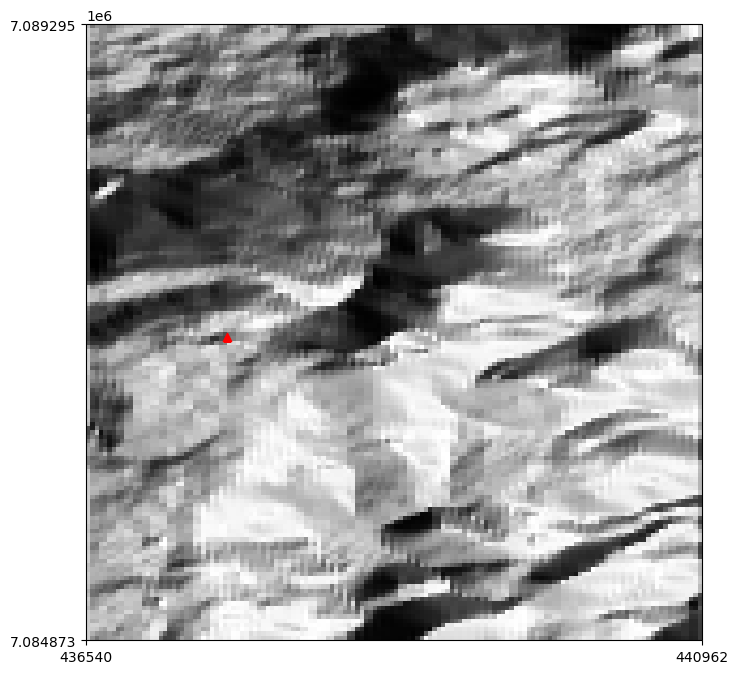

In [7]:
fig = plt.figure(figsize=(12, 8))
ax = plt.axes(projection=ccrs.epsg(32627))
victor.plot_dem("fagradalsfjall.asc", coords = numpy.array([utm_east,utm_north]))

### Now that we've visualized the DEM, please extract a 1km elevation profile due east from the vent.

For ease of use, we recommend using the `rioxarray` package, which extracts raster data into an Xarray DataArray, which has ample documentation available.

### <span style="color:blue"> Solution Notes: `rioxarray` has its strength in one file, `open_rasterio`, as you can see below. After running that line, the DEM becomes an Xarray `DataArray`, which allows for very easy slicing. As an example, I show the actual elevation values from the `DataArray` named `demarray`.

In [8]:
demarray = rxr.open_rasterio("fagradalsfjall.asc")

In [9]:
demarray.values

array([[[114.22865 , 114.22865 , 115.5291  , ..., 272.16574 ,
         267.8935  , 267.8935  ],
        [114.193054, 114.193054, 114.8243  , ..., 270.1556  ,
         266.1382  , 266.1382  ],
        [113.00721 , 113.00721 , 113.961334, ..., 267.3884  ,
         264.85416 , 264.85416 ],
        ...,
        [271.24643 , 271.24643 , 271.35727 , ..., 188.57788 ,
         192.69934 , 192.69934 ],
        [270.53156 , 270.53156 , 271.1702  , ..., 198.88333 ,
         203.64822 , 203.64822 ],
        [270.00632 , 270.00632 , 271.22516 , ..., 209.13107 ,
         215.04684 , 215.04684 ]]], dtype=float32)

### <span style="color:blue"> Solution Notes: Though possible to do in one line, I took a more gradual approach. In the first line, I take an inclusive cut of any values that are within a vertical slice between the chosen coordinate and a kilometer to the east. The second line takes only the y coordinate nearest the northing.

In [10]:
demarray_cut = demarray.sel(x=slice(utm_east, utm_east+1000))
demarray_cut = demarray_cut.sel(y=utm_north, method="nearest")
demarray_cut

<xarray.DataArray (band: 1, x: 33)>
array([[346.0427 , 345.89035, 345.89035, 345.2166 , 345.2166 , 343.90887,
        343.90887, 342.13007, 342.13007, 340.93988, 340.93988, 341.92578,
        341.92578, 343.04028, 343.04028, 343.7125 , 343.7125 , 344.09576,
        344.09576, 344.64856, 344.64856, 345.5731 , 345.5731 , 345.30167,
        345.30167, 345.38666, 345.38666, 348.3811 , 348.3811 , 353.63092,
        353.63092, 360.9422 , 360.9422 ]], dtype=float32)
Coordinates:
  * band         (band) int64 1
  * x            (x) float64 4.376e+05 4.376e+05 ... 4.385e+05 4.386e+05
    y            float64 7.087e+06
    spatial_ref  int64 0
Attributes:
    _FillValue:    0.0
    scale_factor:  1.0
    add_offset:    0.0

### After extracting that data, plot the data using Xarray's built in plotting functionality

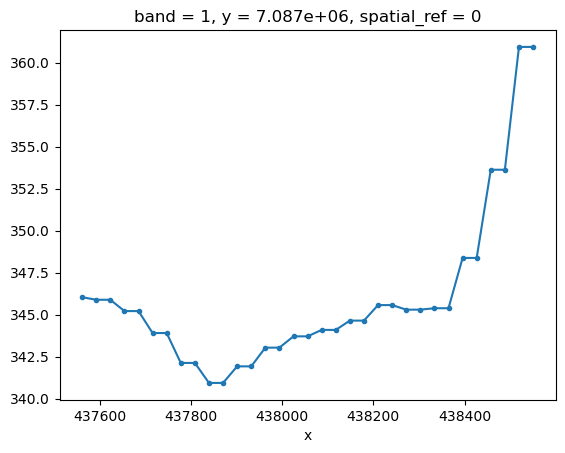

In [11]:
demarray_cut.plot(marker=".")

### Continuing on, calculate the slopes along this profile values using `numpy`

The `arctan2` function is recommended here. Make sure to think about how to calculate the y distance between each value.

### <span style="color:blue"> Solution Notes: A slew of small calculations must be done here to format the data properly. First, one must find the distance between the cells, which I approached through merely finding the difference between the second and first indices.<br><br>The next cell calculates the differences in elevation, and creates an array with the same dimensions of the height array `y_dist`, populating it with the cell size.<br><br>Next, one must find the arctan values, and convert them to degrees. <br><br> Finally, I created a linearly spaced array over the kilometer with the correct number of cells (i.e., `len(x_dist)`). From here, a standard plot can be made with the distance on the x axis and slope on the y axis.
</span>

In [12]:
#distance between
x_dist = demarray_cut.x[1]-demarray_cut.x[0]

In [13]:
y_dist = numpy.diff(demarray_cut.values)[0]
x_dist = numpy.full_like(y_dist, x_dist)

In [14]:
slope = numpy.degrees(numpy.arctan2(y_dist,x_dist))

In [15]:
dist_vent = numpy.linspace(0,1000,len(x_dist))

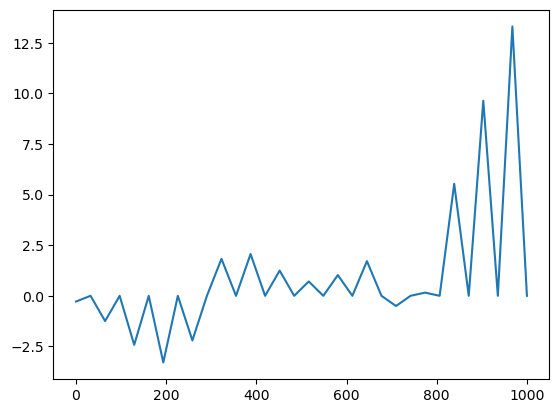

In [16]:
plt.plot(dist_vent, slope)

### Finally, save the slopes information in a tab-separated text file of the format:

    x	 y	z	Dist	SLOPE

### with the headers *exactly* as shown above. 

This will allow us to use the file on pyFLOWGO, which does simulations of channelized lava and accounts forthermo-rheological properties.

Hint: Use `numpy` and `pandas`, and make sure all columns are equal length.

### <span style="color:blue"> Solution Notes: Below, additional data formatting is required. My approach was to first populate the northing and easting values, followed by deleting the final element to account for the loss of a value due to the slope calculations. The elevation values, assigned to `z`, is similarly truncated. To calcualte the overall distance, we must do a cumulative sum. Finally, the arrays are formatted into a Python dictionary, which pandas can easily convert into a `DataFrame`, which can thus be saved to a tab separated text file, as shown in the final cell.

In [17]:
y_vals = numpy.full_like(demarray_cut.x, float(demarray_cut.y))
x_vals = demarray_cut.x.values
y_vals = numpy.delete(y_vals,-1)
x_vals = numpy.delete(x_vals,-1)
z = numpy.delete(demarray_cut.values[0],-1)
dist = numpy.cumsum(x_dist)
data = {'x': x_vals, 'y': y_vals, 'z': z, 'Dist': dist,'SLOPE':slope}
df = pd.DataFrame(data)

In [18]:
df.to_csv('example.txt', sep="\t",index=False)